# 1. IMPORT LIBRARY

In [8]:
pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import joblib
import shap
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 2. LOAD MODEL

In [10]:
MODEL_PATH = Path("../models")

model = joblib.load(
    MODEL_PATH / "xgb_feature_AB.pkl"
)

encoder = joblib.load(
    MODEL_PATH / "label_encoder.pkl"
)

# 3. LOAD DATASET

In [ ]:
DATA_PATH = Path("../data/processed")
feature_AB = pd.read_csv(
    DATA_PATH / "feature_AB.csv"
)

# 4. PISAHKAN FEATURE

In [12]:
X = feature_AB.drop(
    columns=["user_id", "label", "source_folder"]
)

# 5. SHAP 

In [13]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X) 

# 6. PLOT

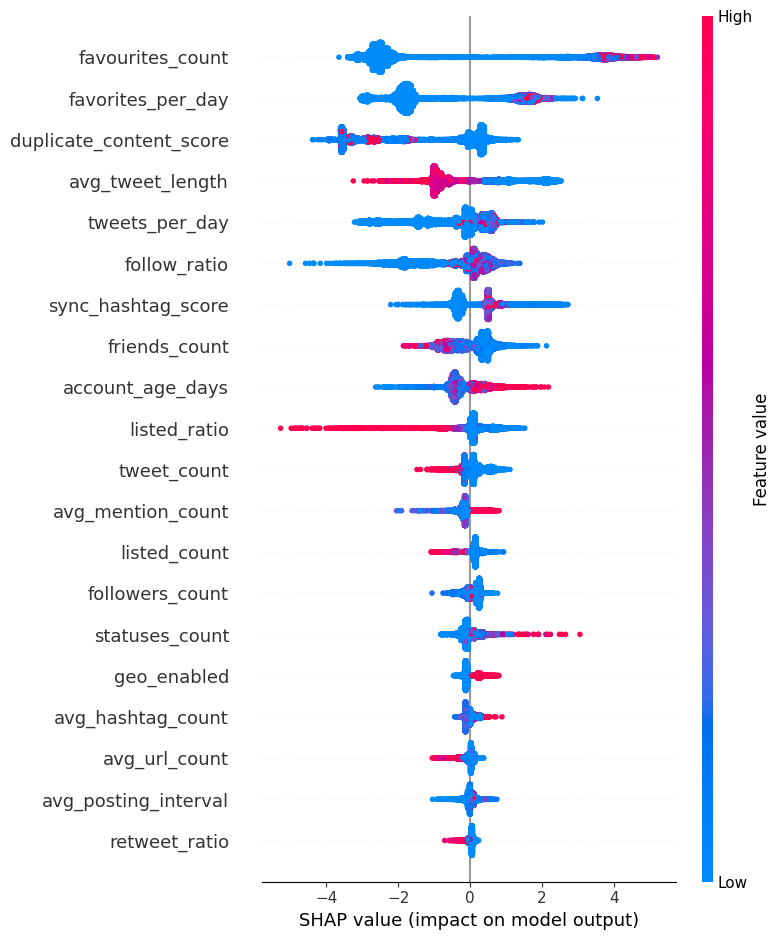

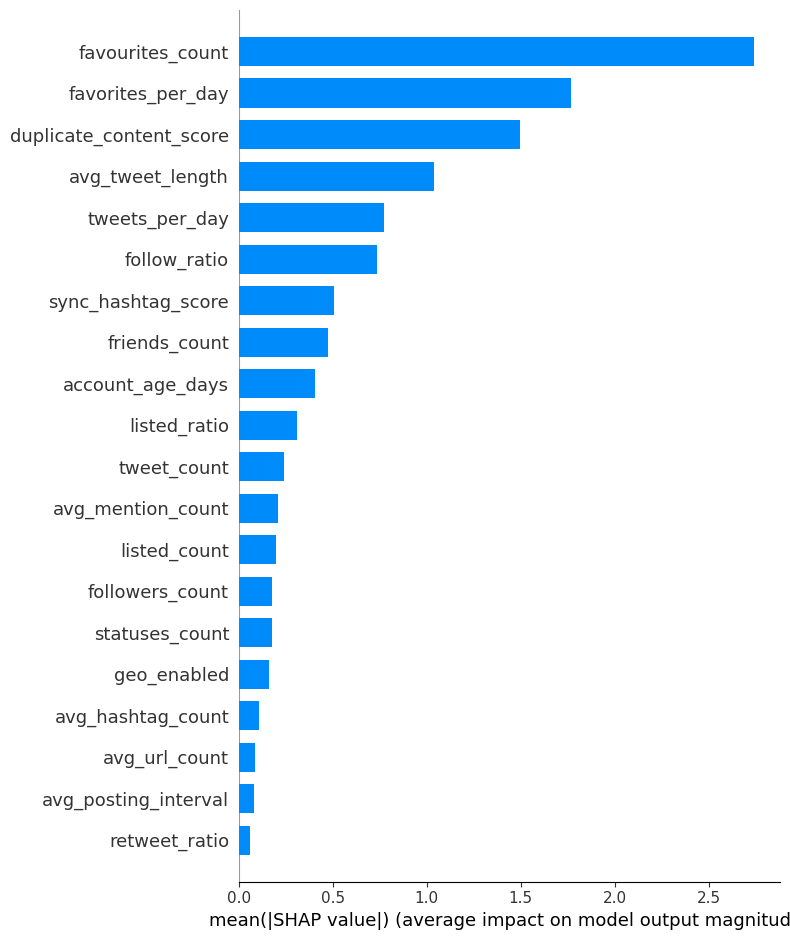

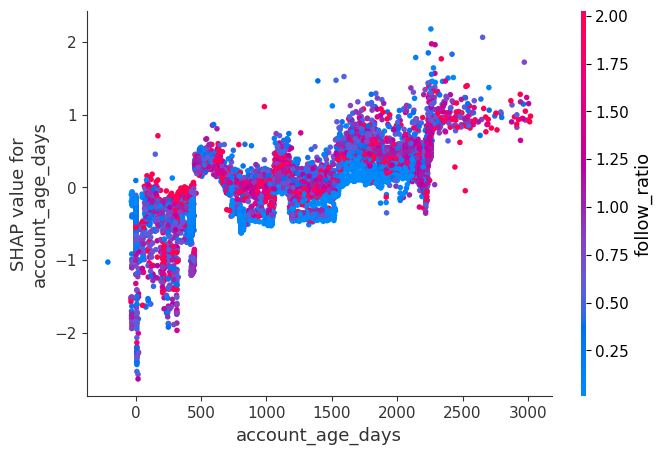

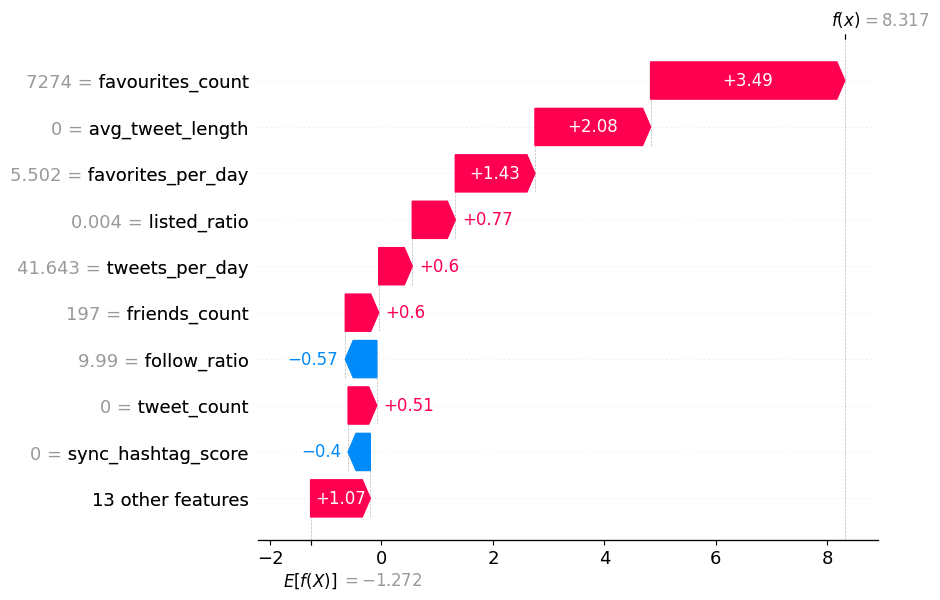

In [ ]:
shap.summary_plot(shap_values, X)
shap.summary_plot(shap_values, X, plot_type="bar")
shap.dependence_plot("account_age_days", shap_values, X)
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[0], X.iloc[0])
shap.plots.waterfall(shap.Explanation(
    values=shap_values[20],
    base_values=explainer.expected_value,
    data=X.iloc[20],
    feature_names=X.columns
))

# 7. TOP 20 FEATURE

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": abs(shap_values).mean(axis=0)
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
4,favourites_count,2.743041
11,favorites_per_day,1.766401
21,duplicate_content_score,1.496623
14,avg_tweet_length,1.038520
10,tweets_per_day,0.772325
9,follow_ratio,0.736749
20,sync_hashtag_score,0.507981
1,friends_count,0.475387
8,account_age_days,0.406266
12,listed_ratio,0.311314


# 8. VISUALISASI

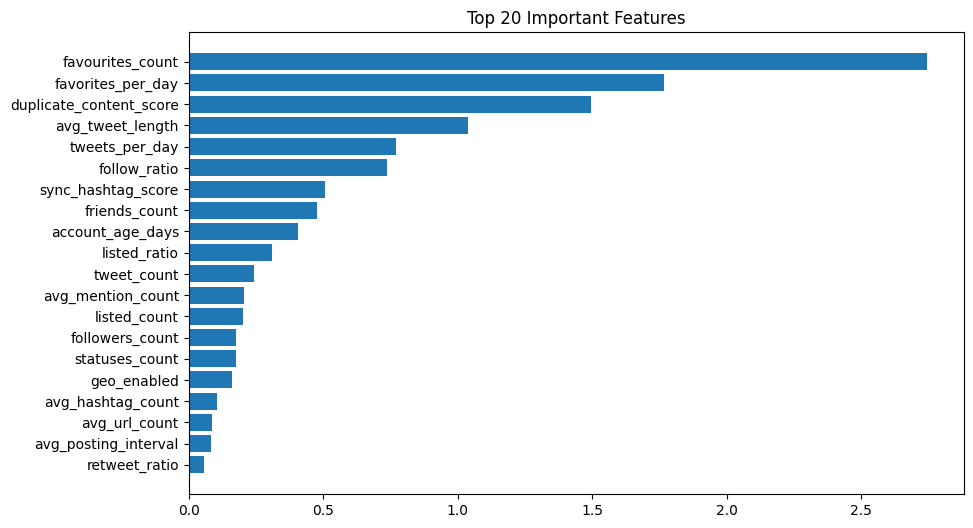

In [ ]:
plt.figure(figsize=(10,6))

plt.barh(
    importance["Feature"][:20],
    importance["Importance"][:20]
)

plt.gca().invert_yaxis()
plt.title("Top 20 Important Features")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

# 9. SAVE

In [ ]:
importance.to_csv(
    "../results/shap_importance.csv",
    index=False
)